# 10 · Maneuver timeline on unseen videos

The full pipeline on videos from outside the dataset: a window slides over the video, the surfer is detected and cropped in each window, the crop is encoded by V-JEPA 2 and a linear probe trained on all surfer crops gives the class probabilities. Consecutive windows with the same label are merged into segments.

The training data has no "no maneuver" class, so a window is labeled **none** when the top probability is low or the surfer is not visible.

External videos (Pexels License, free to use; not redistributed in this repository):

| file | Pexels id | content |
|---|---|---|
| pexels_1 | 4927323 | close tracking shot, several turns with spray, likely slow motion |
| pexels_2 | 4929633 | same style, longer, several maneuvers |
| pexels_3 | 40203014 | side view from the beach, closest to contest footage |
| pexels_4 | 4927723 | female surfer, turns, backlit |
| pexels_5 | 37705001 | vertical 9:16, barrel exit and a turn |
| pexels_6 | 15706062 | kitesurfing, not surfing (found on inspection), high oblique camera |
| pexels_7 | 19912272 | top-down drone view (a camera angle absent from training) |

## 1. Setup

In [1]:
import sys
from pathlib import Path

# Make the project root importable (notebooks/ is one level below it)
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

import cv2
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch                      # imported before ultralytics so it is fully initialized first
from ultralytics import YOLO

from src.data.features import load_features
from src.data.inventory import DATA_DIR
from src.inference.timeline import label_windows, read_video, to_segments
from src.models.encoder import VJEPA2Encoder
from src.models.evaluate import linear_probe

splits = pd.read_csv(PROJECT_ROOT / "data" / "splits.csv")
VIDEOS = sorted((PROJECT_ROOT / "data" / "external").glob("pexels_*.mp4"))

detector = YOLO("yolo26s.pt")
encoder = VJEPA2Encoder()
print(len(VIDEOS), "external videos:", [v.name for v in VIDEOS])

c:\Users\fabri\Desktop\Portfolio\surf-maneuver-recognition\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1118 13:51:54.475000 23520 .venv\Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.
[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 587/587 [00:02<00:00, 235.37it/s]


7 external videos: ['pexels_1.mp4', 'pexels_2.mp4', 'pexels_3.mp4', 'pexels_4.mp4', 'pexels_5.mp4', 'pexels_6.mp4', 'pexels_7.mp4']


## 2. Window length from the training clips

In [2]:
def duration_s(path):
    """Clip duration from the container metadata (no decoding needed)."""
    cap = cv2.VideoCapture(str(path))
    frames, fps = cap.get(cv2.CAP_PROP_FRAME_COUNT), cap.get(cv2.CAP_PROP_FPS)
    cap.release()
    return frames / fps

durations = splits["clip"].map(lambda c: duration_s(DATA_DIR / c))
print(durations.describe(percentiles=[0.1, 0.5, 0.9]).round(2))

# One window = a typical training clip; the window moves by a quarter of its length
WINDOW_S = round(durations.median(), 1)
STRIDE_S = WINDOW_S / 4
SAMPLE_FPS = 12   # enough frames per window to pick 16 evenly spaced ones
print(f"\nwindow {WINDOW_S}s | stride {STRIDE_S:.2f}s | sampling {SAMPLE_FPS} fps")

count    1056.00
mean        2.77
std         1.34
min         0.83
10%         1.77
50%         2.57
90%         3.57
max        15.48
Name: clip, dtype: float64

window 2.6s | stride 0.65s | sampling 12 fps


## 3. Final classifier on surfer crops

In [3]:
# Trained on every clip: evaluation was done with cross-validation in notebooks 06–09
X_surfer = load_features(splits, "vjepa2_vitl_t8_surfer").mean(axis=1)
probe = linear_probe().fit(X_surfer, splits["maneuver"].to_numpy())
classes = list(probe.classes_)

# Saved for the demo app (small file, versioned)
MODEL_FILE = PROJECT_ROOT / "models" / "linear_probe_surfer.joblib"
MODEL_FILE.parent.mkdir(exist_ok=True)
joblib.dump(probe, MODEL_FILE)
print(classes, "| saved to", MODEL_FILE.relative_to(PROJECT_ROOT))

['360', 'cutback-frontside', 'roller', 'take-off'] | saved to models\linear_probe_surfer.joblib


## 4. Timeline on the external videos

In [4]:
MIN_CONFIDENCE = 0.6     # below this top-class probability, the window is labeled "none"
MIN_SURFER_FRAMES = 8    # the surfer must be found in at least 8 of the 16 frames

results = {}
for path in VIDEOS:
    frames, fps = read_video(path, SAMPLE_FPS)
    windows = label_windows(frames, fps, WINDOW_S, STRIDE_S, detector, encoder, probe)
    segments = to_segments(windows, classes, MIN_CONFIDENCE, MIN_SURFER_FRAMES)
    results[path.stem] = (windows, segments)

    print(f"\n=== {path.stem}: {len(frames) / fps:.1f}s, {len(windows)} windows")
    print(segments.assign(start_s=segments["start_s"].round(1), end_s=segments["end_s"].round(1)).to_string(index=False))


=== pexels_1: 18.3s, 24 windows
   label  start_s  end_s  confidence
take-off      0.0    9.9        0.88
  roller      8.0   10.6        0.67
    none      8.7   11.3        0.59
  roller      9.3   12.6        0.81
take-off     10.7   18.0        0.98

=== pexels_2: 27.6s, 38 windows
   label  start_s  end_s  confidence
take-off      0.0    5.3        0.93
    none      3.3    5.9        0.58
  roller      4.0    6.6        0.76
take-off      4.7   15.3        0.89
    none     13.3   15.9        0.51
  roller     14.0   17.3        0.97
take-off     15.3   24.6        0.88
    none     22.7   26.0        0.52
take-off     24.0   27.3        0.75

=== pexels_3: 23.0s, 33 windows
            label  start_s  end_s  confidence
         take-off      0.0    3.8        0.81
             none      1.9    4.5        0.56
           roller      2.6    7.7        0.97
             none      5.8    8.3        0.58
           roller      6.4    9.6        0.75
             none      7.7   10.9

## 5. Timeline plots

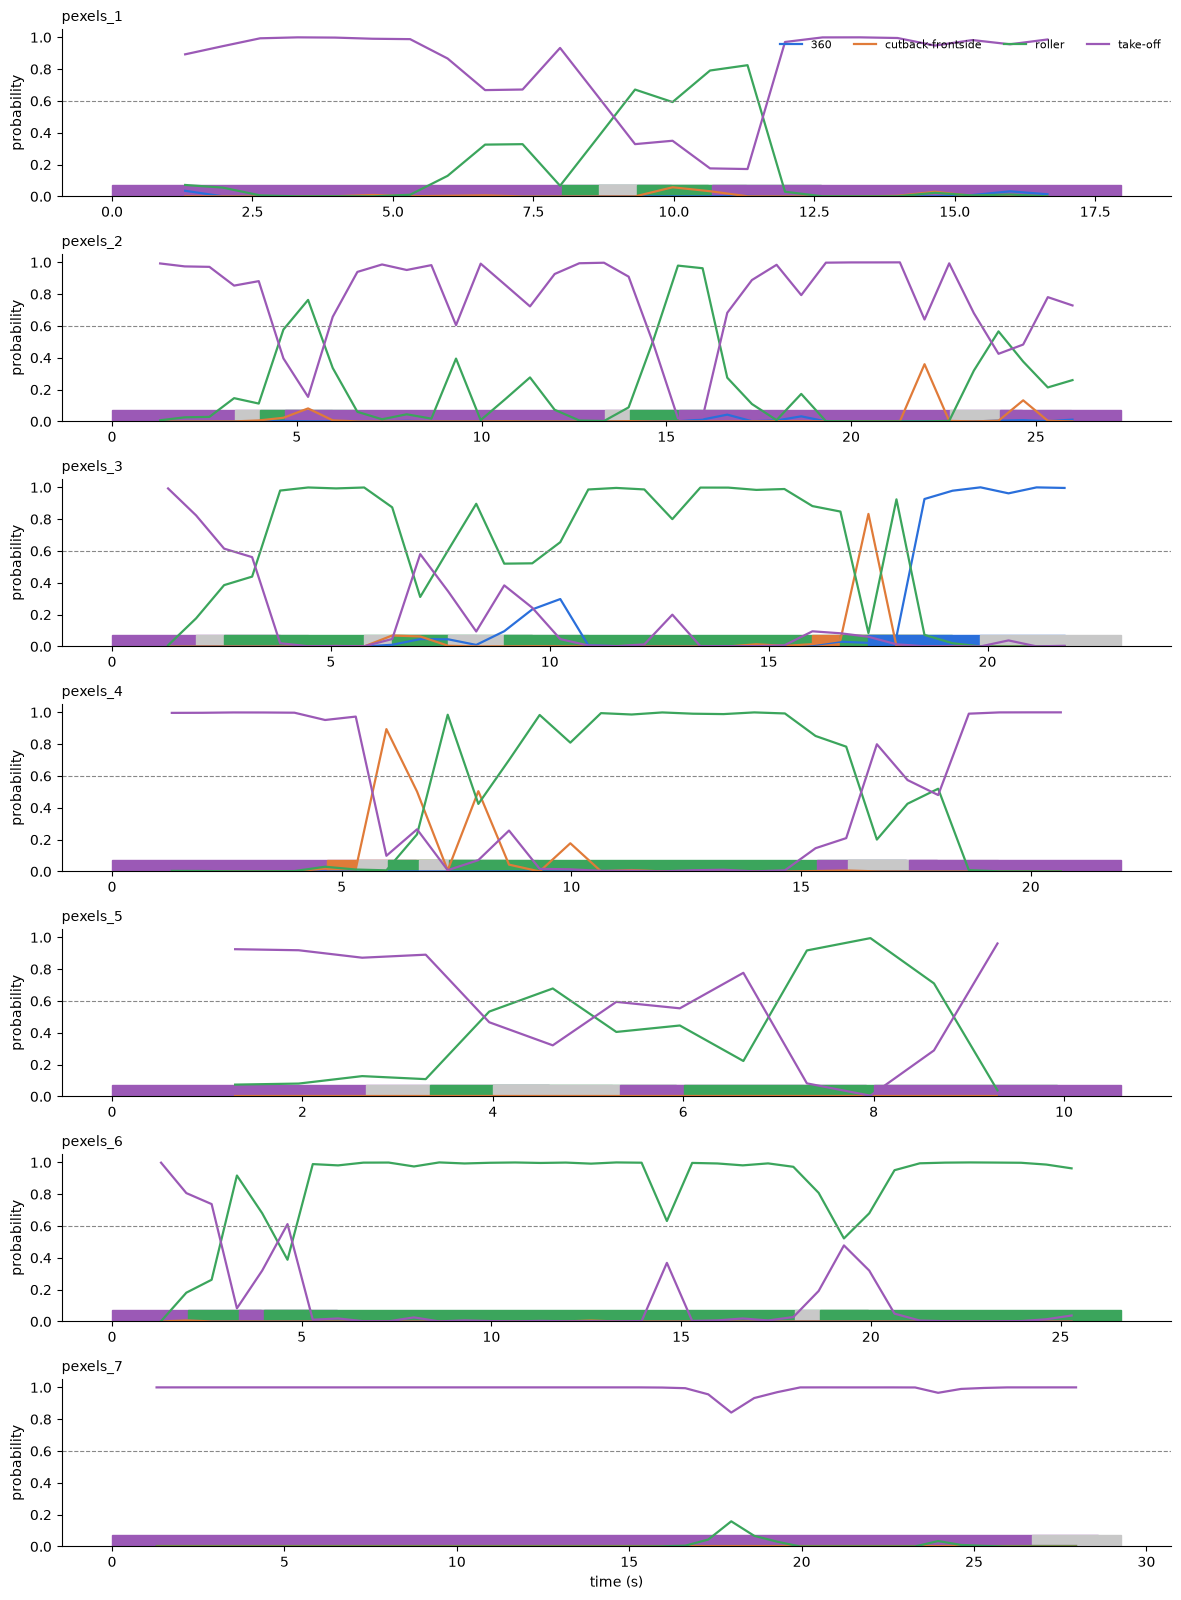

In [5]:
# Fixed color per class (never by rank), gray for "none"
colors = {"360": "#2A6FDB", "cutback-frontside": "#E07B39", "roller": "#3BA55C",
          "take-off": "#9B59B6", "none": "#C8C8C8"}

fig, axes = plt.subplots(len(results), 1, figsize=(12, 2.3 * len(results)), squeeze=False)
for ax, (name, (windows, segments)) in zip(axes[:, 0], results.items()):
    centers = (windows["start_s"] + windows["end_s"]) / 2
    probs = windows.reindex(columns=classes)
    for c in classes:
        ax.plot(centers, probs[c], color=colors[c], lw=1.6, label=c)
    # Segment band along the bottom: the label the timeline would show
    for _, seg in segments.iterrows():
        ax.axvspan(seg["start_s"], seg["end_s"], ymin=0, ymax=0.07, color=colors[seg["label"]])
    ax.axhline(MIN_CONFIDENCE, color="#888888", ls="--", lw=0.8)
    ax.set_ylim(0, 1.05)
    ax.set_ylabel("probability")
    ax.set_title(name, loc="left", fontsize=10)
    ax.spines[["top", "right"]].set_visible(False)

axes[0, 0].legend(ncol=4, fontsize=8, loc="upper right", frameon=False)
axes[-1, 0].set_xlabel("time (s)")
plt.tight_layout()
fig.savefig(PROJECT_ROOT / "reports" / "figures" / "timeline_external_videos.png", dpi=150)
plt.show()

## 6. Out-of-distribution check

In [6]:
K = 10   # neighbors used to measure how familiar a clip looks

# Reference: cosine distance from each training clip to its K nearest training clips from OTHER sessions
# (same-session neighbors are near-duplicates and would make every clip look familiar)
Z = X_surfer / np.linalg.norm(X_surfer, axis=1, keepdims=True)
distances = 1 - Z @ Z.T
groups = splits["group"].to_numpy()
distances[groups[:, None] == groups[None, :]] = np.inf
train_knn = np.sort(distances, axis=1)[:, :K].mean(axis=1)
OOD_THRESHOLD = np.quantile(train_knn, 0.95)
print(f"training clips: median kNN distance {np.median(train_knn):.3f}, 95th percentile {OOD_THRESHOLD:.3f}")

def knn_distance(features):
    """Mean cosine distance from each feature vector to its K nearest training clips."""
    z = features / np.linalg.norm(features, axis=1, keepdims=True)
    return np.sort(1 - z @ Z.T, axis=1)[:, :K].mean(axis=1)

summary = []
for name, (windows, _) in results.items():
    has_surfer = windows["features"].notna().to_numpy()
    d = np.full(len(windows), np.nan)
    d[has_surfer] = knn_distance(np.stack(windows.loc[has_surfer, "features"]))
    windows["knn_distance"] = d
    summary.append({"video": name, "median_knn_distance": np.nanmedian(d),
                    "windows_out_of_distribution": np.nanmean(d > OOD_THRESHOLD)})
pd.DataFrame(summary).round(3)

training clips: median kNN distance 0.032, 95th percentile 0.059


,video,median_knn_distance,windows_out_of_distribution
0,pexels_1,0.101,1.000
1,pexels_2,0.101,1.000
2,pexels_3,0.067,0.727
3,pexels_4,0.055,0.400
4,pexels_5,0.103,1.000
5,pexels_6,0.168,1.000
6,pexels_7,0.152,1.000


In [9]:
# Timeline again, with out-of-distribution windows forced to "none"
for name, (windows, _) in results.items():
    flagged = windows.copy()
    flagged.loc[flagged["knn_distance"] > OOD_THRESHOLD, classes] = np.nan
    segments = to_segments(flagged, classes, MIN_CONFIDENCE, MIN_SURFER_FRAMES)
    print(f"\n=== {name}")
    print(segments.assign(start_s=segments["start_s"].round(1), end_s=segments["end_s"].round(1)).to_string(index=False))


=== pexels_1
label  start_s  end_s  confidence
 none      0.0   18.0         0.0

=== pexels_2
label  start_s  end_s  confidence
 none      0.0   27.3         0.0

=== pexels_3
   label  start_s  end_s  confidence
take-off      0.0    3.8        0.81
    none      1.9    4.5        0.56
  roller      2.6    7.0        0.99
    none      5.1   12.2        0.00
  roller     10.2   12.8        1.00
    none     10.9   23.0        0.00

=== pexels_4
   label  start_s  end_s  confidence
take-off      0.0    5.9        0.99
    none      4.0    7.9        0.00
  roller      6.0    8.6        0.99
    none      6.7    9.3        0.50
  roller      7.3   15.9        0.94
    none     14.0   22.0        0.00

=== pexels_5
label  start_s  end_s  confidence
 none      0.0   10.6         0.0

=== pexels_6
label  start_s  end_s  confidence
 none      0.0   26.6         0.0

=== pexels_7
label  start_s  end_s  confidence
 none      0.0   29.2         0.0


## 7. Findings

Manual annotation (by a surfer, watching each video) against the timeline:

| video | what happens | timeline without OOD check | windows flagged out of distribution |
|---|---|---|---|
| pexels_1 | close tracking shot, slow motion, standing turns throughout | take-off, 0.9–1.0 | 100% |
| pexels_2 | same style, several turns | mostly take-off | 100% |
| pexels_3 | paddle and drop (0–2 s), turns with spray (3–15 s), air attempt and fall (~18 s), surfer gone (20 s+) | take-off → roller → cutback/360 spikes → none | 73% |
| pexels_4 | paddle and drop (0–5 s), something briefly passes in front of the camera (~6–7 s, same wave), riding with no maneuver (7–15 s), weak cutback (15–16 s), exits the wave | take-off ✓, roller 6–16 s ✗, cutback missed | 40% |
| pexels_5 | vertical, slow motion: barrel exit (0–2.6 s, a maneuver outside the 4 classes), a second surfer enters (3.8–5 s), strong cutback on the lip (5.6–9.7 s) | alternating take-off / roller | 100% |
| pexels_6 | kitesurfing (kite line visible), high oblique camera, rider mostly in the whitewater | roller, 0.99 | 100% |
| pexels_7 | top-down drone view, turns | take-off, 0.99 | 100% |

- **The pipeline transfers only to contest-like footage.** On side-view videos similar to the training data (pexels_3, pexels_4), the drop is recognized as take-off and the surfer leaving the frame becomes "none". Close-ups, slow motion, vertical video and drone views are classified wrongly.
- **Softmax confidence does not flag these errors.** Wrong predictions on unfamiliar footage come with 0.9–0.99 confidence, so the 0.6 confidence threshold is no protection.
- **A k-nearest-neighbor distance check does.** Each window is compared with its 10 nearest training clips (cosine distance on surfer-crop features). The threshold is the 95th percentile of the same distance for training clips, measured against clips from other sessions only (same-session near-duplicates would make every clip look familiar). It flags every window of the close-up, slow-motion, drone and kitesurf videos, including kitesurfing, which the classifier had labeled roller at 0.99.
- **The threshold is strict.** It also flags 73% of pexels_3, the most contest-like video. It was not tuned on these 7 videos, which would amount to calibrating on the test set.
- **The main limitation is structural: there is no "no maneuver" class.** In pexels_4 the surfer rides for about 8 s without a maneuver and the timeline says roller (0.94), the majority class. Those windows look like normal contest footage, so the distance check cannot catch them either. Temporal segmentation of real sessions needs negative examples (riding, paddling, waiting) in the training data.